# Clasificación de Malware Android mediante Machine Learning

**Actividad:** Dataset - Notebook | Individual  

**Curso:** TC5061  

**Alumno:** Josafat Misael Rodríguez Nieto

**Matrícula:** A01840189

**Dataset:** TUANDROMD

**Fuente:** UCI Machine Learning Repository  

## Objetivo

El objetivo de este notebook es desarrollar un flujo base de Machine Learning para la clasificación de aplicaciones Android como malware o goodware a partir de características relacionadas con permisos y llamadas a API.

El proceso comprende la exploración y descripción del conjunto de datos, análisis exploratorio (EDA), evaluación de la calidad y limpieza de los datos, entrenamiento de un modelo baseline, evaluación de su desempeño y registro del experimento mediante MLflow Tracking.

El propósito no es obtener el modelo con el mayor desempeño posible, sino establecer un punto de partida sencillo, interpretable y reproducible que pueda utilizarse como referencia para experimentos posteriores.

In [1]:
# Librerías para manipulación y análisis de datos
import pandas as pd
import numpy as np

# Librerías para visualización
import matplotlib.pyplot as plt

# Configuración de reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configuración de visualización de pandas
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print(f"Semilla aleatoria: {RANDOM_STATE}")

Semilla aleatoria: 42


## 1. Carga del dataset

Para este experimento se utiliza el dataset **TUANDROMD**, disponible en el [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/813/tunadromd). Este conjunto de datos está orientado a la clasificación de aplicaciones Android y contiene características relacionadas con permisos y llamadas a API.

El dataset se carga programáticamente desde UCI para facilitar la reproducibilidad del experimento. Posteriormente, se inspeccionará su estructura antes de realizar cualquier transformación o limpieza.

> **Nota de reproducibilidad:** para ejecutar el notebook en Google Colab, el archivo `TUANDROMD.csv` debe encontrarse en el directorio de trabajo de la sesión.

In [5]:
# Cargar el dataset desde el archivo CSV
df = pd.read_csv("TUANDROMD.csv")

print("Dataset cargado correctamente.")
print(f"Número de registros: {df.shape[0]}")
print(f"Número de variables: {df.shape[1]}")

Dataset cargado correctamente.
Número de registros: 4465
Número de variables: 242


In [6]:
# Visualizar las primeras cinco observaciones
df.head()

,ACCESS_ALL_DOWNLOADS,ACCESS_CACHE_FILESYSTEM,ACCESS_CHECKIN_PROPERTIES,ACCESS_COARSE_LOCATION,ACCESS_COARSE_UPDATES,ACCESS_FINE_LOCATION,ACCESS_LOCATION_EXTRA_COMMANDS,ACCESS_MOCK_LOCATION,ACCESS_MTK_MMHW,ACCESS_NETWORK_STATE,ACCESS_PROVIDER,ACCESS_SERVICE,ACCESS_SHARED_DATA,ACCESS_SUPERUSER,ACCESS_SURFACE_FLINGER,ACCESS_WIFI_STATE,activityCalled,ACTIVITY_RECOGNITION,ACCOUNT_MANAGER,ADD_VOICEMAIL,ANT,ANT_ADMIN,AUTHENTICATE_ACCOUNTS,AUTORUN_MANAGER_LICENSE_MANAGER,AUTORUN_MANAGER_LICENSE_SERVICE(.autorun),...,Ljava/lang/System;->load,Ldalvik/system/DexClassLoader;->loadClass,Ljava/lang/System;->loadLibrary,Ljava/net/URL;->openConnection,Landroid/hardware/Camera;->open,Landroid/hardware/Camera;->takePicture,Landroid/telephony/SmsManager;->sendMultipartTextMessage,Landroid/telephony/SmsManager;->sendTextMessage,Landroid/media/AudioRecord;->startRecording,Landroid/telephony/TelephonyManager;->getCellLocation,Lcom/google/android/gms/location/LocationClient;->getLastLocation,Landroid/location/LocationManager;->getLastK0wnLocation,Landroid/telephony/TelephonyManager;->getDeviceId,Landroid/content/pm/PackageManager;->getInstalledApplications,Landroid/content/pm/PackageManager;->getInstalledPackages,Landroid/telephony/TelephonyManager;->getLine1Number,Landroid/telephony/TelephonyManager;->getNetworkOperator,Landroid/telephony/TelephonyManager;->getNetworkOperatorName,Landroid/telephony/TelephonyManager;->getNetworkCountryIso,Landroid/telephony/TelephonyManager;->getSimOperator,Landroid/telephony/TelephonyManager;->getSimOperatorName,Landroid/telephony/TelephonyManager;->getSimCountryIso,Landroid/telephony/TelephonyManager;->getSimSerialNumber,Lorg/apache/http/impl/client/DefaultHttpClient;->execute,Label
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [7]:
# Inspeccionar los nombres de las variables
print("Variables disponibles en el dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Variables disponibles en el dataset:

1. ACCESS_ALL_DOWNLOADS
2. ACCESS_CACHE_FILESYSTEM
3. ACCESS_CHECKIN_PROPERTIES
4. ACCESS_COARSE_LOCATION
5. ACCESS_COARSE_UPDATES
6. ACCESS_FINE_LOCATION
7. ACCESS_LOCATION_EXTRA_COMMANDS
8. ACCESS_MOCK_LOCATION
9. ACCESS_MTK_MMHW
10. ACCESS_NETWORK_STATE
11. ACCESS_PROVIDER
12. ACCESS_SERVICE
13. ACCESS_SHARED_DATA
14. ACCESS_SUPERUSER
15. ACCESS_SURFACE_FLINGER
16. ACCESS_WIFI_STATE
17. activityCalled
18. ACTIVITY_RECOGNITION
19. ACCOUNT_MANAGER
20. ADD_VOICEMAIL
21. ANT
22. ANT_ADMIN
23. AUTHENTICATE_ACCOUNTS
24. AUTORUN_MANAGER_LICENSE_MANAGER
25. AUTORUN_MANAGER_LICENSE_SERVICE(.autorun)
26. BATTERY_STATS
27. BILLING
28. BIND_ACCESSIBILITY_SERVICE
29. BIND_APPWIDGET
30. BIND_CARRIER_MESSAGING_SERVICE
31. BIND_DEVICE_ADMIN
32. BIND_DREAM_SERVICE
33. BIND_GET_INSTALL_REFERRER_SERVICE
34. BIND_INPUT_METHOD
35. BIND_NFC_SERVICE
36. BIND_0TIFICATION_LISTENER_SERVICE
37. BIND_PRINT_SERVICE
38. BIND_REMOTEVIEWS
39. BIND_TEXT_SERVICE
40. BIND_TV_INPU

In [8]:
# Revisar la estructura general y los tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4465 entries, 0 to 4464
Columns: 242 entries, ACCESS_ALL_DOWNLOADS to Label
dtypes: float64(242)
memory usage: 8.2 MB


## 2. Descripción y estructura del dataset

Antes de realizar el análisis exploratorio y la limpieza, se examina la estructura del conjunto de datos, los tipos de variables y la distribución de la variable objetivo. Esta inspección permite comprender cómo están representadas las características utilizadas para distinguir entre aplicaciones maliciosas y benignas.

In [9]:
# Resumen general de la estructura del dataset
print("Resumen del dataset")
print("-" * 40)
print(f"Número de registros: {df.shape[0]}")
print(f"Número total de columnas: {df.shape[1]}")
print(f"Número de características predictoras: {df.shape[1] - 1}")
print(f"Variable objetivo: Label")

print("\nTipos de datos:")
print(df.dtypes.value_counts())

Resumen del dataset
----------------------------------------
Número de registros: 4465
Número total de columnas: 242
Número de características predictoras: 241
Variable objetivo: Label

Tipos de datos:
float64    242
Name: count, dtype: int64


In [10]:
# Examinar los valores de la variable objetivo
print("Valores presentes en Label:")
print(df["Label"].value_counts(dropna=False).sort_index())

print("\nProporción de cada clase:")
print(
    df["Label"]
    .value_counts(normalize=True, dropna=False)
    .sort_index()
    .mul(100)
    .round(2)
)

Valores presentes en Label:
Label
0.0     899
1.0    3565
NaN       1
Name: count, dtype: int64

Proporción de cada clase:
Label
0.0    20.13
1.0    79.84
NaN     0.02
Name: proportion, dtype: float64


In [11]:
# Analizar los valores únicos presentes en las características
feature_columns = df.columns.drop("Label")

unique_values = set(
    np.unique(df[feature_columns].values)
)

print("Valores únicos encontrados en las características:")
print(sorted(unique_values))

if unique_values.issubset({0.0, 1.0}):
    print("\nTodas las características son binarias.")
else:
    print("\nExisten características con valores distintos de 0 y 1.")

Valores únicos encontrados en las características:
[np.float64(0.0), np.float64(1.0), np.float64(nan)]

Existen características con valores distintos de 0 y 1.


In [12]:
# Verificar valores faltantes y duplicados de manera preliminar
print(f"Valores faltantes totales: {df.isnull().sum().sum()}")
print(f"Registros duplicados: {df.duplicated().sum()}")

Valores faltantes totales: 242
Registros duplicados: 3802


In [13]:
# Identificar las columnas que contienen valores faltantes
missing_values = df.isnull().sum()
missing_columns = missing_values[missing_values > 0].sort_values(ascending=False)

print(f"Columnas con valores faltantes: {len(missing_columns)}")
print(f"Total de valores faltantes: {missing_columns.sum()}")

display(missing_columns)

Columnas con valores faltantes: 242
Total de valores faltantes: 242


,0
ACCESS_ALL_DOWNLOADS,1
ACCESS_CACHE_FILESYSTEM,1
ACCESS_CHECKIN_PROPERTIES,1
ACCESS_COARSE_LOCATION,1
ACCESS_COARSE_UPDATES,1
...,...
Landroid/telephony/TelephonyManager;->getSimOperatorName,1
Landroid/telephony/TelephonyManager;->getSimCountryIso,1
Landroid/telephony/TelephonyManager;->getSimSerialNumber,1
Lorg/apache/http/impl/client/DefaultHttpClient;->execute,1


In [14]:
# Identificar las filas que contienen valores faltantes
rows_with_missing = df[df.isnull().any(axis=1)]

print(f"Filas con al menos un valor faltante: {len(rows_with_missing)}")

display(rows_with_missing)

Filas con al menos un valor faltante: 1


,ACCESS_ALL_DOWNLOADS,ACCESS_CACHE_FILESYSTEM,ACCESS_CHECKIN_PROPERTIES,ACCESS_COARSE_LOCATION,ACCESS_COARSE_UPDATES,ACCESS_FINE_LOCATION,ACCESS_LOCATION_EXTRA_COMMANDS,ACCESS_MOCK_LOCATION,ACCESS_MTK_MMHW,ACCESS_NETWORK_STATE,ACCESS_PROVIDER,ACCESS_SERVICE,ACCESS_SHARED_DATA,ACCESS_SUPERUSER,ACCESS_SURFACE_FLINGER,ACCESS_WIFI_STATE,activityCalled,ACTIVITY_RECOGNITION,ACCOUNT_MANAGER,ADD_VOICEMAIL,ANT,ANT_ADMIN,AUTHENTICATE_ACCOUNTS,AUTORUN_MANAGER_LICENSE_MANAGER,AUTORUN_MANAGER_LICENSE_SERVICE(.autorun),...,Ljava/lang/System;->load,Ldalvik/system/DexClassLoader;->loadClass,Ljava/lang/System;->loadLibrary,Ljava/net/URL;->openConnection,Landroid/hardware/Camera;->open,Landroid/hardware/Camera;->takePicture,Landroid/telephony/SmsManager;->sendMultipartTextMessage,Landroid/telephony/SmsManager;->sendTextMessage,Landroid/media/AudioRecord;->startRecording,Landroid/telephony/TelephonyManager;->getCellLocation,Lcom/google/android/gms/location/LocationClient;->getLastLocation,Landroid/location/LocationManager;->getLastK0wnLocation,Landroid/telephony/TelephonyManager;->getDeviceId,Landroid/content/pm/PackageManager;->getInstalledApplications,Landroid/content/pm/PackageManager;->getInstalledPackages,Landroid/telephony/TelephonyManager;->getLine1Number,Landroid/telephony/TelephonyManager;->getNetworkOperator,Landroid/telephony/TelephonyManager;->getNetworkOperatorName,Landroid/telephony/TelephonyManager;->getNetworkCountryIso,Landroid/telephony/TelephonyManager;->getSimOperator,Landroid/telephony/TelephonyManager;->getSimOperatorName,Landroid/telephony/TelephonyManager;->getSimCountryIso,Landroid/telephony/TelephonyManager;->getSimSerialNumber,Lorg/apache/http/impl/client/DefaultHttpClient;->execute,Label
2533,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
# Analizar la cantidad de combinaciones repetidas considerando
# todas las características y la etiqueta
duplicate_mask = df.duplicated(keep=False)

print(f"Filas que pertenecen a algún grupo repetido: {duplicate_mask.sum()}")
print(f"Duplicados adicionales detectados por pandas: {df.duplicated().sum()}")
print(f"Combinaciones únicas completas: {df.drop_duplicates().shape[0]}")

Filas que pertenecen a algún grupo repetido: 4113
Duplicados adicionales detectados por pandas: 3802
Combinaciones únicas completas: 663


In [16]:
# Verificar si una misma combinación de características
# aparece asociada con diferentes etiquetas
feature_columns = df.columns.drop("Label")

label_variation = (
    df.dropna()
      .groupby(list(feature_columns))["Label"]
      .nunique()
)

conflicting_patterns = (label_variation > 1).sum()

print(
    "Patrones de características asociados con más de una clase:",
    conflicting_patterns
)

Patrones de características asociados con más de una clase: 2


In [18]:
# Crear una copia sin valores faltantes para el análisis
df_complete = df.dropna().copy()

# Columnas predictoras
feature_columns = df_complete.columns.drop("Label").tolist()

# Identificar patrones de características asociados con más de una etiqueta
label_counts = (
    df_complete
    .groupby(feature_columns, sort=False, observed=True)["Label"]
    .nunique()
)

# Seleccionar únicamente los patrones conflictivos
conflicting_index = label_counts[label_counts > 1].index

print(f"Patrones conflictivos encontrados: {len(conflicting_index)}")

Patrones conflictivos encontrados: 2


In [19]:
# Crear un identificador para cada combinación de características
pattern_id = pd.util.hash_pandas_object(
    df_complete[feature_columns],
    index=False
)

# Crear una tabla auxiliar con el patrón y su etiqueta
pattern_analysis = pd.DataFrame({
    "pattern_id": pattern_id,
    "Label": df_complete["Label"].values
})

# Identificar patrones que aparecen con ambas etiquetas
conflicting_ids = (
    pattern_analysis
    .groupby("pattern_id")["Label"]
    .nunique()
)

conflicting_ids = conflicting_ids[conflicting_ids > 1].index

# Recuperar las observaciones involucradas
conflicting_rows = pattern_analysis[
    pattern_analysis["pattern_id"].isin(conflicting_ids)
]

print(f"Observaciones involucradas en patrones conflictivos: {len(conflicting_rows)}")

print("\nDistribución de etiquetas:")
display(
    conflicting_rows["Label"]
    .value_counts()
    .sort_index()
)

Observaciones involucradas en patrones conflictivos: 83

Distribución de etiquetas:


,count
Label,
0.0,54
1.0,29


In [20]:
# Analizar la distribución de valores faltantes por fila
missing_per_row = df.isnull().sum(axis=1)

print("Distribución de valores faltantes por fila:")
display(
    missing_per_row
    .value_counts()
    .sort_index()
)

print("\nFilas con valores faltantes:")
display(
    df[df.isnull().any(axis=1)]
)

Distribución de valores faltantes por fila:


,count
0,4464
242,1



Filas con valores faltantes:


,ACCESS_ALL_DOWNLOADS,ACCESS_CACHE_FILESYSTEM,ACCESS_CHECKIN_PROPERTIES,ACCESS_COARSE_LOCATION,ACCESS_COARSE_UPDATES,ACCESS_FINE_LOCATION,ACCESS_LOCATION_EXTRA_COMMANDS,ACCESS_MOCK_LOCATION,ACCESS_MTK_MMHW,ACCESS_NETWORK_STATE,ACCESS_PROVIDER,ACCESS_SERVICE,ACCESS_SHARED_DATA,ACCESS_SUPERUSER,ACCESS_SURFACE_FLINGER,ACCESS_WIFI_STATE,activityCalled,ACTIVITY_RECOGNITION,ACCOUNT_MANAGER,ADD_VOICEMAIL,ANT,ANT_ADMIN,AUTHENTICATE_ACCOUNTS,AUTORUN_MANAGER_LICENSE_MANAGER,AUTORUN_MANAGER_LICENSE_SERVICE(.autorun),...,Ljava/lang/System;->load,Ldalvik/system/DexClassLoader;->loadClass,Ljava/lang/System;->loadLibrary,Ljava/net/URL;->openConnection,Landroid/hardware/Camera;->open,Landroid/hardware/Camera;->takePicture,Landroid/telephony/SmsManager;->sendMultipartTextMessage,Landroid/telephony/SmsManager;->sendTextMessage,Landroid/media/AudioRecord;->startRecording,Landroid/telephony/TelephonyManager;->getCellLocation,Lcom/google/android/gms/location/LocationClient;->getLastLocation,Landroid/location/LocationManager;->getLastK0wnLocation,Landroid/telephony/TelephonyManager;->getDeviceId,Landroid/content/pm/PackageManager;->getInstalledApplications,Landroid/content/pm/PackageManager;->getInstalledPackages,Landroid/telephony/TelephonyManager;->getLine1Number,Landroid/telephony/TelephonyManager;->getNetworkOperator,Landroid/telephony/TelephonyManager;->getNetworkOperatorName,Landroid/telephony/TelephonyManager;->getNetworkCountryIso,Landroid/telephony/TelephonyManager;->getSimOperator,Landroid/telephony/TelephonyManager;->getSimOperatorName,Landroid/telephony/TelephonyManager;->getSimCountryIso,Landroid/telephony/TelephonyManager;->getSimSerialNumber,Lorg/apache/http/impl/client/DefaultHttpClient;->execute,Label
2533,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Limpieza y preparación de los datos

La evaluación de calidad identificó un registro completamente vacío, con valores faltantes en las 242 variables. Debido a que esta observación no contiene información predictora ni una etiqueta de clase, se elimina del conjunto de datos en lugar de aplicar algún método de imputación.

También se identificó una cantidad considerable de patrones repetidos. Sin embargo, estos registros no se eliminan automáticamente, ya que el dataset representa las aplicaciones mediante un conjunto limitado de características binarias. Por lo tanto, diferentes aplicaciones pueden compartir exactamente la misma representación.

Adicionalmente, se encontraron dos patrones de características asociados con ambas clases, involucrando 83 observaciones (54 de una clase y 29 de la otra). Esto indica que las características disponibles no permiten distinguir completamente todas las observaciones. Estas muestras se conservan para evitar modificar arbitrariamente las etiquetas originales del dataset.

Finalmente, debido a que las características están representadas mediante valores binarios (0 y 1), no se aplica eliminación convencional de valores atípicos. En este contexto, ambos valores representan estados válidos de presencia o ausencia de una característica.

In [21]:
# Crear una copia para preservar el dataset original
df_clean = df.copy()

# Eliminar registros completamente vacíos
df_clean = df_clean.dropna(how="all").reset_index(drop=True)

print(f"Registros antes de la limpieza: {len(df)}")
print(f"Registros después de eliminar filas vacías: {len(df_clean)}")
print(f"Valores faltantes restantes: {df_clean.isnull().sum().sum()}")

Registros antes de la limpieza: 4465
Registros después de eliminar filas vacías: 4464
Valores faltantes restantes: 0


In [22]:
# Verificar nuevamente que todos los valores sean binarios
unique_values = np.unique(df_clean.values)

print("Valores únicos presentes en el dataset:")
print(unique_values)

Valores únicos presentes en el dataset:
[0. 1.]


In [23]:
# Convertir las variables binarias de float a integer
df_clean = df_clean.astype("int8")

print("Tipos de datos después de la conversión:")
print(df_clean.dtypes.value_counts())

print(f"\nUso de memoria: {df_clean.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Tipos de datos después de la conversión:
int8    242
Name: count, dtype: int64

Uso de memoria: 1.03 MB


In [24]:
# Validación final de la calidad del dataset limpio
print("Validación final")
print("-" * 40)
print(f"Dimensiones: {df_clean.shape}")
print(f"Valores faltantes: {df_clean.isnull().sum().sum()}")
print(f"Duplicados exactos conservados: {df_clean.duplicated().sum()}")
print(f"Valores únicos posibles: {sorted(np.unique(df_clean.values))}")
print(f"Tipos de datos: {df_clean.dtypes.unique()}")

Validación final
----------------------------------------
Dimensiones: (4464, 242)
Valores faltantes: 0
Duplicados exactos conservados: 3802
Valores únicos posibles: [np.int8(0), np.int8(1)]
Tipos de datos: [dtype('int8')]


## 4. Análisis exploratorio de datos (EDA)

El análisis exploratorio se enfoca en la distribución de la variable objetivo y en la frecuencia de las características binarias. Debido a que las variables predictoras representan principalmente la presencia o ausencia de permisos y llamadas a API, las visualizaciones convencionales para variables continuas, como histogramas o diagramas de caja, no resultan apropiadas.

En su lugar, se analiza el balance entre clases, la prevalencia de las características y las diferencias en su frecuencia entre las dos clases.

In [25]:
# Distribución de la variable objetivo
class_counts = df_clean["Label"].value_counts().sort_index()
class_percentages = (
    df_clean["Label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

class_distribution = pd.DataFrame({
    "Cantidad": class_counts,
    "Porcentaje": class_percentages.round(2)
})

display(class_distribution)

,Cantidad,Porcentaje
Label,,
0,899,20.14
1,3565,79.86


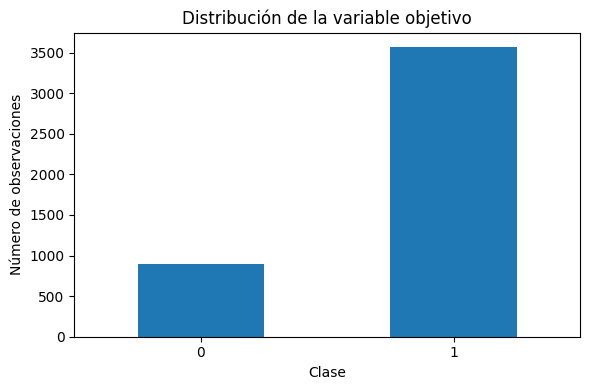

In [26]:
# Visualizar la distribución de clases
ax = class_counts.plot(
    kind="bar",
    figsize=(6, 4)
)

ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de observaciones")
ax.set_xticklabels(["0", "1"], rotation=0)

plt.tight_layout()
plt.show()

In [27]:
# Calcular la frecuencia de aparición de cada característica
feature_columns = df_clean.columns.drop("Label")

feature_frequency = (
    df_clean[feature_columns]
    .mean()
    .sort_values(ascending=False)
)

print("10 características más frecuentes:")
display(
    (feature_frequency.head(10) * 100)
    .round(2)
    .to_frame("Porcentaje de observaciones (%)")
)

10 características más frecuentes:


,Porcentaje de observaciones (%)
WAKE_LOCK,88.55
RECEIVE_BOOT_COMPLETED,84.36
INTERNET,73.36
GET_TASKS,64.14
ACCESS_NETWORK_STATE,59.63
Ljava/lang/reflect/Method;->invoke,55.02
READ_PHONE_STATE,53.54
Ljavax/crypto/Cipher;->doFinal,51.66
KILL_BACKGROUND_PROCESSES,50.43
WRITE_EXTERNAL_STORAGE,44.13


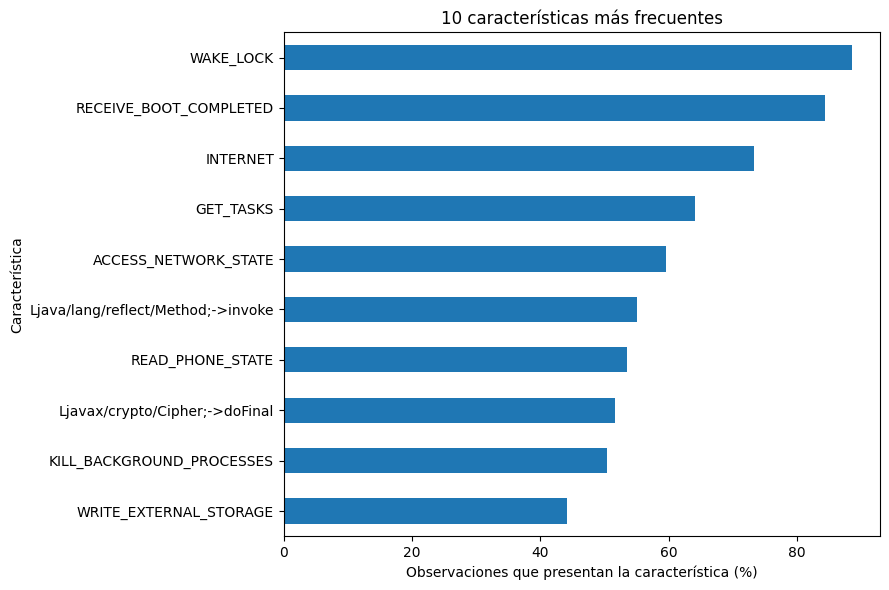

In [28]:
# Visualizar las 10 características más frecuentes
top_features = (feature_frequency.head(10) * 100).sort_values()

ax = top_features.plot(
    kind="barh",
    figsize=(9, 6)
)

ax.set_title("10 características más frecuentes")
ax.set_xlabel("Observaciones que presentan la característica (%)")
ax.set_ylabel("Característica")

plt.tight_layout()
plt.show()

### 4.1 Comparación de características entre clases

La frecuencia general de una característica no implica necesariamente que esta sea útil para distinguir entre las clases. Por ello, se compara la proporción de observaciones que presentan cada característica dentro de cada clase.

Para cada variable se calcula la diferencia absoluta entre su frecuencia en las clases 0 y 1. Una diferencia mayor indica que la característica presenta un comportamiento más distinto entre ambas clases y, por lo tanto, podría aportar información útil al modelo de clasificación.

In [29]:
# Calcular la frecuencia de cada característica dentro de cada clase
feature_by_class = (
    df_clean
    .groupby("Label")[feature_columns]
    .mean()
    .T
)

# Renombrar columnas para facilitar su interpretación
feature_by_class.columns = ["Clase_0", "Clase_1"]

# Calcular diferencia absoluta entre clases
feature_by_class["Diferencia"] = (
    feature_by_class["Clase_1"] -
    feature_by_class["Clase_0"]
).abs()

# Ordenar por mayor diferencia
top_discriminative = (
    feature_by_class
    .sort_values("Diferencia", ascending=False)
    .head(10)
    .copy()
)

# Convertir proporciones a porcentajes
top_discriminative = top_discriminative * 100

display(top_discriminative.round(2))

,Clase_0,Clase_1,Diferencia
RECEIVE_BOOT_COMPLETED,29.37,98.23,68.87
Ljava/net/URL;->openConnection,72.41,4.24,68.18
GET_TASKS,10.34,77.70,67.36
KILL_BACKGROUND_PROCESSES,6.79,61.43,54.65
Landroid/location/LocationManager;->getLastK0wnLocation,54.95,1.49,53.46
Ljava/lang/System;->load,41.94,3.56,38.37
WAKE_LOCK,58.62,96.10,37.48
Ljava/lang/System;->loadLibrary,39.15,3.23,35.93
Landroid/telephony/TelephonyManager;->getNetworkOperator,52.84,17.42,35.42
SYSTEM_ALERT_WINDOW,12.46,46.79,34.33


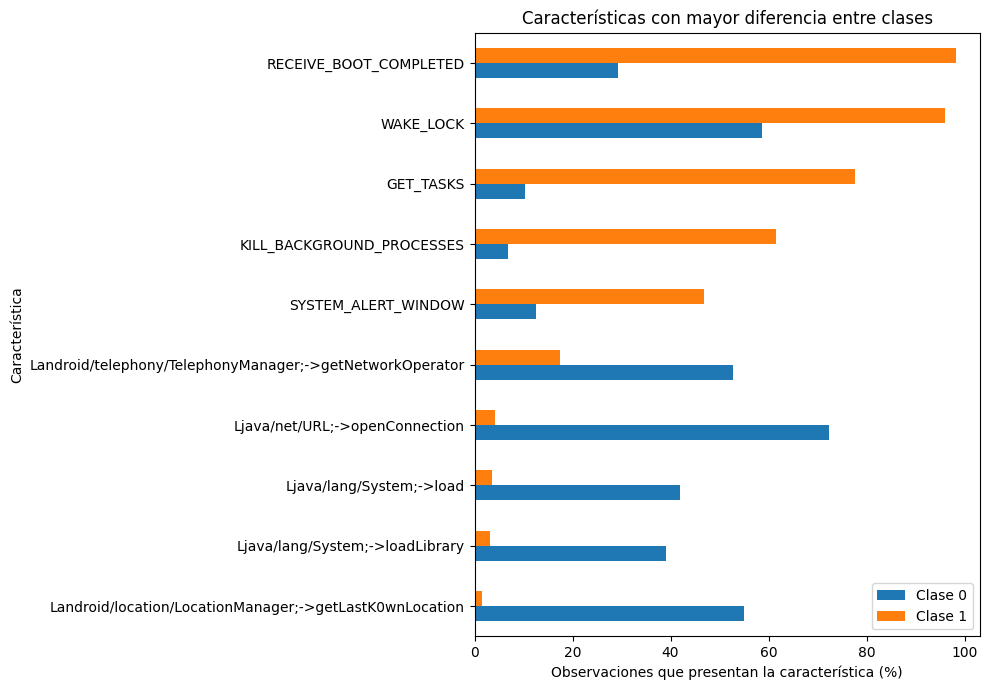

In [30]:
# Comparar las características con mayor diferencia entre clases
plot_data = (
    top_discriminative[["Clase_0", "Clase_1"]]
    .sort_values("Clase_1")
)

ax = plot_data.plot(
    kind="barh",
    figsize=(10, 7)
)

ax.set_title("Características con mayor diferencia entre clases")
ax.set_xlabel("Observaciones que presentan la característica (%)")
ax.set_ylabel("Característica")
ax.legend(["Clase 0", "Clase 1"])

plt.tight_layout()
plt.show()

In [31]:
# Estadísticos descriptivos de las características binarias
descriptive_stats = df_clean[feature_columns].describe().T

# Agregar porcentaje de presencia para facilitar interpretación
descriptive_stats["Presencia (%)"] = (
    descriptive_stats["mean"] * 100
).round(2)

display(
    descriptive_stats[
        ["count", "mean", "std", "min", "max", "Presencia (%)"]
    ]
    .sort_values("Presencia (%)", ascending=False)
    .head(15)
)

,count,mean,std,min,max,Presencia (%)
WAKE_LOCK,4464.0,0.885529,0.318419,0.0,1.0,88.55
RECEIVE_BOOT_COMPLETED,4464.0,0.843638,0.363239,0.0,1.0,84.36
INTERNET,4464.0,0.733647,0.442101,0.0,1.0,73.36
GET_TASKS,4464.0,0.641353,0.479657,0.0,1.0,64.14
ACCESS_NETWORK_STATE,4464.0,0.596326,0.490689,0.0,1.0,59.63
Ljava/lang/reflect/Method;->invoke,4464.0,0.550179,0.497531,0.0,1.0,55.02
READ_PHONE_STATE,4464.0,0.535394,0.498802,0.0,1.0,53.54
Ljavax/crypto/Cipher;->doFinal,4464.0,0.516577,0.499781,0.0,1.0,51.66
KILL_BACKGROUND_PROCESSES,4464.0,0.504256,0.500038,0.0,1.0,50.43
WRITE_EXTERNAL_STORAGE,4464.0,0.441308,0.496599,0.0,1.0,44.13


### 4.2 Interpretación del análisis exploratorio

El conjunto de datos presenta un desbalance importante en la variable objetivo. La clase 1 representa el 79.86 % de las observaciones (3,565 registros), mientras que la clase 0 representa el 20.14 % (899 registros). Por esta razón, la exactitud (accuracy) no será suficiente por sí sola para evaluar el modelo, ya que un clasificador que predijera únicamente la clase mayoritaria podría alcanzar aproximadamente 79.86 % de accuracy sin aprender patrones útiles.

El análisis de frecuencia muestra que algunas de las características más comunes en el conjunto de datos son `WAKE_LOCK` (88.55 %), `RECEIVE_BOOT_COMPLETED` (84.36 %) e `INTERNET` (73.36 %). Sin embargo, la comparación entre clases revela diferencias más relevantes para la clasificación.

Por ejemplo, `RECEIVE_BOOT_COMPLETED` está presente en 98.23 % de las observaciones de la clase 1, frente a 29.37 % de la clase 0, una diferencia de 68.87 puntos porcentuales. `GET_TASKS` presenta un comportamiento similar, con 77.70 % en la clase 1 y 10.34 % en la clase 0. En sentido contrario, `Ljava/net/URL;->openConnection` aparece en 72.41 % de la clase 0 y únicamente en 4.24 % de la clase 1.

Estos resultados muestran que existen características con distribuciones claramente diferentes entre las dos clases, lo cual sugiere que las variables disponibles contienen información útil para construir un modelo de clasificación. No obstante, ninguna característica debe interpretarse individualmente como evidencia suficiente de una clase; el modelo utilizará la combinación de múltiples variables para realizar sus predicciones.

## 5. Modelo baseline

Se utilizará un árbol de decisión como modelo baseline. Este algoritmo es adecuado como punto de partida debido a que puede trabajar directamente con características binarias, permite capturar relaciones no lineales y ofrece una interpretación relativamente sencilla.

Debido a la existencia de múltiples observaciones con patrones de características idénticos, se evitará una división aleatoria convencional por observación. Si un mismo patrón apareciera tanto en entrenamiento como en prueba, la evaluación podría sobreestimar la capacidad de generalización del modelo.

Por esta razón, las observaciones se agrupan de acuerdo con su combinación de características y se utiliza una división por grupos, de forma que un mismo patrón no pueda aparecer simultáneamente en los conjuntos de entrenamiento y prueba.

In [32]:
# Separar características predictoras y variable objetivo
X = df_clean.drop(columns="Label")
y = df_clean["Label"]

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

Dimensiones de X: (4464, 241)
Dimensiones de y: (4464,)


In [33]:
# Crear un identificador para cada patrón único de características
groups = pd.util.hash_pandas_object(
    X,
    index=False
)

print(f"Observaciones totales: {len(X)}")
print(f"Patrones únicos de características: {groups.nunique()}")

Observaciones totales: 4464
Patrones únicos de características: 660


In [34]:
from sklearn.model_selection import GroupShuffleSplit

# Configurar división 80 % entrenamiento / 20 % prueba
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print(f"Observaciones de entrenamiento: {len(X_train)}")
print(f"Observaciones de prueba: {len(X_test)}")

print("\nDistribución de clases - entrenamiento:")
display(
    (y_train.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nDistribución de clases - prueba:")
display(
    (y_test.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Observaciones de entrenamiento: 2903
Observaciones de prueba: 1561

Distribución de clases - entrenamiento:


,proportion
Label,
0,25.46
1,74.54



Distribución de clases - prueba:


,proportion
Label,
0,10.25
1,89.75


In [35]:
# Verificar que ningún patrón aparezca en ambos conjuntos
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

overlap = train_groups.intersection(test_groups)

print(f"Patrones compartidos entre entrenamiento y prueba: {len(overlap)}")

Patrones compartidos entre entrenamiento y prueba: 0


### 5.1 Entrenamiento del modelo

Se utiliza un árbol de decisión como modelo baseline. Para mantener el experimento sencillo y reproducible, no se realiza optimización de hiperparámetros en esta etapa. Se utiliza una profundidad máxima de 5 para limitar la complejidad del árbol y reducir el riesgo de sobreajuste.

La división por grupos produjo 2,903 observaciones de entrenamiento y 1,561 de prueba. Aunque la proporción de observaciones no corresponde exactamente a 80/20, se conserva esta división porque el método separa patrones únicos de características y evita que representaciones idénticas aparezcan simultáneamente en entrenamiento y prueba.

In [36]:
from sklearn.tree import DecisionTreeClassifier

# Crear el modelo baseline
baseline_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=RANDOM_STATE
)

# Entrenar el modelo
baseline_model.fit(X_train, y_train)

print("Modelo entrenado correctamente.")
print(f"Profundidad del árbol: {baseline_model.get_depth()}")
print(f"Número de hojas: {baseline_model.get_n_leaves()}")

Modelo entrenado correctamente.
Profundidad del árbol: 5
Número de hojas: 25


In [37]:
# Generar predicciones sobre el conjunto de prueba
y_pred = baseline_model.predict(X_test)

print(f"Predicciones generadas: {len(y_pred)}")
print(f"Clases predichas: {np.unique(y_pred)}")

Predicciones generadas: 1561
Clases predichas: [0 1]


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calcular métricas del modelo
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print("Métricas del modelo baseline")
print("-" * 35)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

Métricas del modelo baseline
-----------------------------------
Accuracy:  0.9590
Precision: 0.9919
Recall:    0.9622
F1-score:  0.9768

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.7376    0.9313    0.8232       160
           1     0.9919    0.9622    0.9768      1401

    accuracy                         0.9590      1561
   macro avg     0.8648    0.9467    0.9000      1561
weighted avg     0.9658    0.9590    0.9611      1561



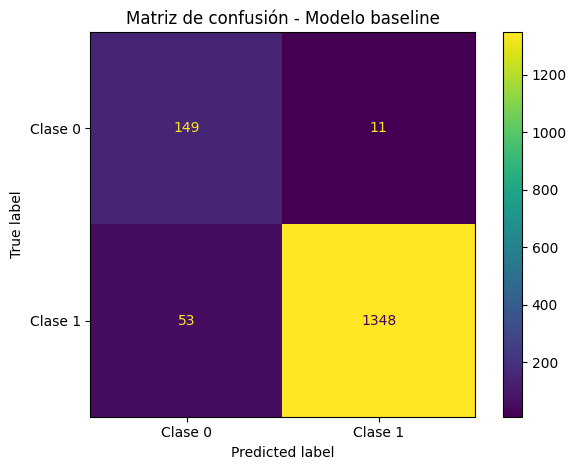

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

# Visualizar matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Clase 0", "Clase 1"],
    values_format="d"
)

plt.title("Matriz de confusión - Modelo baseline")
plt.tight_layout()
plt.show()

In [40]:
# Baseline ingenuo: predecir siempre la clase mayoritaria del conjunto de entrenamiento
majority_class = y_train.mode()[0]

naive_predictions = np.full(
    len(y_test),
    majority_class
)

naive_accuracy = accuracy_score(
    y_test,
    naive_predictions
)

print(f"Clase mayoritaria en entrenamiento: {majority_class}")
print(f"Accuracy del baseline ingenuo: {naive_accuracy:.4f}")
print(f"Accuracy del árbol de decisión: {accuracy:.4f}")
print(f"Mejora absoluta: {(accuracy - naive_accuracy):.4f}")

Clase mayoritaria en entrenamiento: 1
Accuracy del baseline ingenuo: 0.8975
Accuracy del árbol de decisión: 0.9590
Mejora absoluta: 0.0615


### 5.2 Evaluación e interpretación del modelo baseline

El árbol de decisión alcanzó una exactitud (accuracy) de 95.90 %, superando el 89.75 % que obtendría un clasificador ingenuo al predecir siempre la clase mayoritaria. Esto representa una mejora absoluta de 6.15 puntos porcentuales, lo que indica que el modelo está aprendiendo patrones adicionales y no solamente aprovechando el desbalance existente en los datos.

Para la clase 1, el modelo obtuvo una precisión de 99.19 %, un recall de 96.22 % y un F1-score de 97.68 %. De las 1,401 observaciones de esta clase presentes en el conjunto de prueba, 1,348 fueron clasificadas correctamente y 53 fueron clasificadas como clase 0.

Para la clase 0, el modelo obtuvo una precisión de 73.76 %, recall de 93.13 % y F1-score de 82.32 %. De las 160 observaciones de esta clase, 149 fueron identificadas correctamente y 11 fueron clasificadas como clase 1.

La matriz de confusión muestra un total de 64 errores sobre 1,561 observaciones de prueba. Aunque el desempeño general es favorable, la diferencia entre las métricas de ambas clases evidencia la importancia de utilizar precision, recall y F1-score además de accuracy en conjuntos de datos desbalanceados.

Finalmente, estos resultados deben interpretarse considerando las características del dataset. Existen patrones repetidos y algunos patrones idénticos asociados con etiquetas diferentes. Para reducir una posible sobreestimación del desempeño, la división de entrenamiento y prueba se realizó agrupando combinaciones idénticas de características, obteniendo cero patrones compartidos entre ambos conjuntos.

## 6. Registro del experimento con MLflow

Para mejorar la trazabilidad y reproducibilidad del experimento, se utiliza MLflow Tracking. Se registran los principales parámetros utilizados para construir el baseline y las métricas obtenidas sobre el conjunto de prueba.

Esto permite conservar de forma estructurada la configuración y los resultados del experimento para facilitar futuras comparaciones.

In [41]:
# Instalar MLflow en el entorno de Google Colab
!pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [42]:
import mlflow
import mlflow.sklearn

print(f"MLflow version: {mlflow.__version__}")

MLflow version: 3.16.1


In [43]:
# Configurar almacenamiento local de MLflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Crear o seleccionar el experimento
mlflow.set_experiment(
    "TUANDROMD_Malware_Classification"
)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento configurado correctamente.")

2026/10/04 23:08:39 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/04 23:08:39 INFO mlflow.store.db.utils: Updating database tables
2026/10/04 23:08:42 INFO mlflow.tracking.fluent: Experiment with name 'TUANDROMD_Malware_Classification' does not exist. Creating a new experiment.


Tracking URI: sqlite:///mlflow.db
Experimento configurado correctamente.


In [45]:
# Registrar un nuevo experimento limpio en MLflow
with mlflow.start_run(run_name="DecisionTree_Baseline") as run:

    # Parámetros del experimento
    mlflow.log_param("model", "DecisionTreeClassifier")
    mlflow.log_param("max_depth", 5)
    mlflow.log_param("random_state", RANDOM_STATE)
    mlflow.log_param("split_method", "GroupShuffleSplit")
    mlflow.log_param("test_size_groups", 0.20)
    mlflow.log_param("n_features", X.shape[1])
    mlflow.log_param("train_samples", len(X_train))
    mlflow.log_param("test_samples", len(X_test))

    # Métricas principales
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision_class_1", precision)
    mlflow.log_metric("recall_class_1", recall)
    mlflow.log_metric("f1_class_1", f1)

    # Obtener métricas de ambas clases
    report = classification_report(
        y_test,
        y_pred,
        output_dict=True
    )

    # Métricas de la clase 0
    mlflow.log_metric(
        "precision_class_0",
        report["0"]["precision"]
    )
    mlflow.log_metric(
        "recall_class_0",
        report["0"]["recall"]
    )
    mlflow.log_metric(
        "f1_class_0",
        report["0"]["f1-score"]
    )

    # Comparación con baseline ingenuo
    mlflow.log_metric(
        "naive_accuracy",
        naive_accuracy
    )

    # Guardar identificador del experimento
    run_id = run.info.run_id

print("Experimento registrado correctamente.")
print(f"Run ID: {run_id}")

Experimento registrado correctamente.
Run ID: 4c4dfc2f279c4e8cb7df5c9e1cd7c796


In [60]:
# Recuperar el experimento registrado en MLflow
experiment = mlflow.get_experiment_by_name(
    "TUANDROMD_Malware_Classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

# Mostrar evidencia de los experimentos registrados
display(
    runs[
        [
            "run_id",
            "tags.mlflow.runName",
            "metrics.accuracy",
            "metrics.f1_class_1",
            "metrics.naive_accuracy",
            "params.model",
            "params.max_depth",
            "params.split_method"
        ]
    ]
)

,run_id,tags.mlflow.runName,metrics.accuracy,metrics.f1_class_1,metrics.naive_accuracy,params.model,params.max_depth,params.split_method
0,4c4dfc2f279c4e8cb7df5c9e1cd7c796,DecisionTree_Baseline,0.959001,0.976812,0.897502,DecisionTreeClassifier,5,GroupShuffleSplit
1,e48560a3feeb4d4cbfb707f5d8f71dcd,DecisionTree_Baseline,0.959001,0.976812,0.897502,DecisionTreeClassifier,5,GroupShuffleSplit


In [63]:
# Descargar la base de datos de MLflow para visualizarla localmente
#from google.colab import files

#files.download("mlflow.db")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 6.1 Evidencia del experimento en MLflow

El experimento `TUANDROMD_Malware_Classification` fue registrado mediante MLflow Tracking. El run `DecisionTree_Baseline` almacena los parámetros utilizados para la configuración del modelo y la estrategia de partición, así como las métricas obtenidas sobre el conjunto de prueba.

Entre las métricas registradas se encuentran accuracy, precision, recall y F1-score para ambas clases, además de la accuracy del clasificador ingenuo utilizado como referencia. Asimismo, se registraron parámetros como la profundidad máxima del árbol, la semilla aleatoria, el método de partición, el número de características y la cantidad de observaciones utilizadas para entrenamiento y prueba.

La siguiente captura muestra la evidencia del experimento registrado en la interfaz de MLflow.

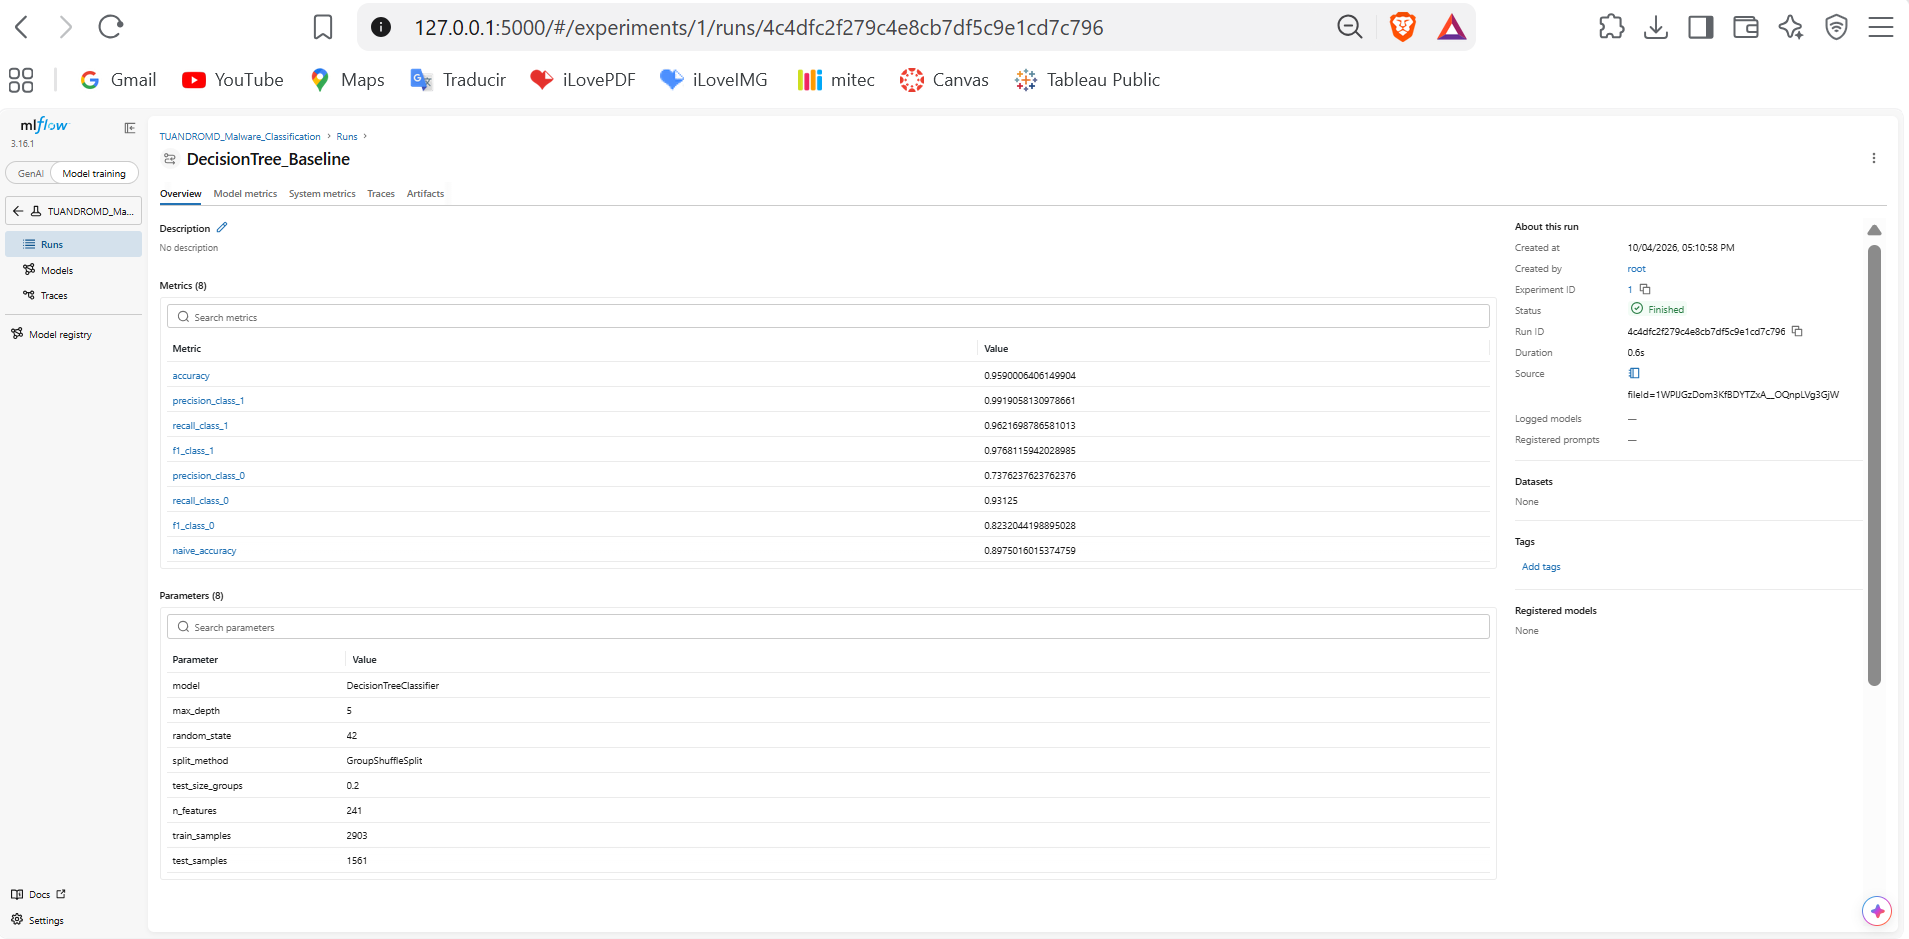

## 7. Reflexión

El desarrollo de este experimento permitió observar que un flujo de Machine Learning no termina con el entrenamiento y la evaluación de un modelo. Desde una perspectiva de MLOps, existen diferentes oportunidades para transformar este baseline en un proceso más robusto y reproducible. Como siguientes pasos, sería conveniente incorporar versionamiento del dataset y del código, validaciones automáticas de calidad de datos, pipelines para las etapas de preparación, entrenamiento y evaluación, así como el registro sistemático de nuevos experimentos. MLflow podría utilizarse para comparar diferentes algoritmos e hiperparámetros y conservar la trazabilidad entre cada versión del modelo y sus resultados.

También sería importante implementar monitoreo una vez que un modelo se encuentre en producción. En un problema relacionado con ciberseguridad, las características y comportamientos asociados con software malicioso pueden cambiar con el tiempo, por lo que el desempeño observado durante el entrenamiento no garantiza el mismo comportamiento ante datos futuros. El monitoreo de métricas, cambios en la distribución de los datos y posibles degradaciones del modelo permitiría identificar cuándo es necesario realizar una nueva evaluación o entrenamiento.

En mi contexto profesional dentro de ciberseguridad y detección de amenazas, este tipo de flujo resulta especialmente relevante. Un modelo de clasificación podría utilizarse como una señal adicional para apoyar procesos de triage y priorización, pero sus resultados no deberían interpretarse de manera aislada. Métricas como precision y recall adquieren importancia porque los falsos positivos pueden incrementar la carga de trabajo de los analistas, mientras que los falsos negativos pueden provocar que actividad potencialmente maliciosa no sea investigada. Por ello, considero que la principal aportación de MLOps en este contexto no consiste únicamente en obtener modelos con métricas altas, sino en construir procesos medibles, trazables, reproducibles y sujetos a evaluación continua.

## 8. Conclusiones

En esta actividad se desarrolló un flujo baseline de Machine Learning para la clasificación de aplicaciones Android utilizando el dataset TUANDROMD. El proceso incluyó la exploración y limpieza de los datos, el análisis de la distribución de las clases y características, la preparación de una estrategia de partición que evitara compartir patrones idénticos entre entrenamiento y prueba, y el entrenamiento de un árbol de decisión.

El modelo alcanzó una accuracy de 95.90 % y superó el 89.75 % obtenido por el clasificador ingenuo basado en la clase mayoritaria. Sin embargo, el análisis por clase mostró diferencias de desempeño que justifican el uso de métricas adicionales como precision, recall y F1-score.

Finalmente, el experimento fue registrado mediante MLflow, permitiendo conservar sus parámetros y métricas de manera estructurada y reproducible. Este baseline establece un punto de referencia para futuras iteraciones en las que podrían evaluarse otros modelos, estrategias de validación y mecanismos de monitoreo.